B2. BERT fills in a blank

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] BertForMaskedLM LOAD REPORT from: google-bert/bert-base-uncased
Key                         | Status     |  | 
----------------------------+------------+--+-
bert.pooler.dense.weight    | UNEXPECTED |  | 
bert.pooler.dense.bias      | UNEXPECTED |  | 
cls.seq_relationship.weight | UNEXPECTED |  | 
cls.seq_relationship.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Sentence 1: I went to the [MASK] to buy some bread.
1. market probability = 0.780005693435669
2. store probability = 0.0561332032084465
3. bakery probability = 0.0467342883348465
4. kitchen probability = 0.022795725613832474
5. markets probability = 0.015057215467095375

Sentence 2: I went to the [MASK] to borrow some books.
1. library probability = 0.7893909215927124
2. bookstore probability = 0.12471672892570496
3. store probability = 0.02394389547407627
4. bathroom probability = 0.006483729463070631
5. office probability = 0.004145338665693998


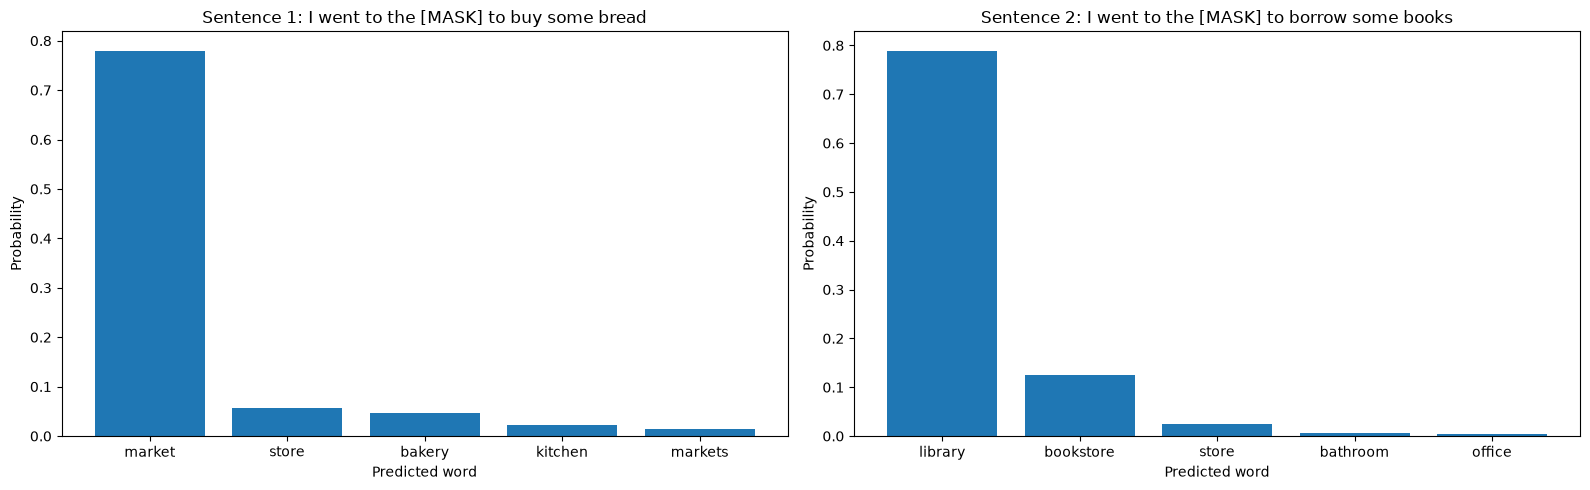

In [1]:
from transformers import pipeline
import matplotlib.pyplot as plt

model_name = "google-bert/bert-base-uncased"
fill_mask = pipeline("fill-mask", model=model_name, tokenizer=model_name, device=0)

sentence1 = "I went to the [MASK] to buy some bread."
sentence2 = "I went to the [MASK] to borrow some books."

result1 = fill_mask(sentence1, top_k=5)
result2 = fill_mask(sentence2, top_k=5)

words1 = []
words2 = []
probs1 = []
probs2 = []

print("Sentence 1:", sentence1)
for i, item in enumerate(result1, 1):
    print(f"{i}. {item['token_str'].strip()} probability = {item['score']}")
    words1.append(item['token_str'])
    probs1.append(item['score'])

print("\nSentence 2:", sentence2)
for i, item in enumerate(result2, 1):
    print(f"{i}. {item['token_str'].strip()} probability = {item['score']}")
    words2.append(item['token_str'])
    probs2.append(item['score'])


fig, axes = plt.subplots(1, 2, figsize=(16, 5))
# sentence 1
axes[0].bar(words1, probs1)
axes[0].set_xlabel("Predicted word")
axes[0].set_ylabel("Probability")
axes[0].set_title("Sentence 1: I went to the [MASK] to buy some bread")

# sentence 2
axes[1].bar(words2, probs2)
axes[1].set_xlabel("Predicted word")
axes[1].set_ylabel("Probability")
axes[1].set_title("Sentence 2: I went to the [MASK] to borrow some books")

plt.tight_layout()
plt.show()

B3. GPT continues a sentence

In [4]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

model_name = "openai-community/gpt2"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForCausalLM.from_pretrained(model_name)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
model.eval()


def top5_next_tokens(text):
    inputs = tokenizer(text, return_tensors="pt").to(device)
    with torch.no_grad():
        outputs = model(**inputs)

    logits = outputs.logits[0, -1, :]
    probs = torch.softmax(logits, dim=-1)
    top_probs, top_ids = torch.topk(probs, 5)
    results = []

    for prob, token_id in zip(top_probs, top_ids):
        token = tokenizer.decode([token_id.item()])
        results.append((token, prob.item()))

    return results

def top5_after_the(full_sentence):
    inputs = tokenizer(full_sentence, return_tensors="pt").to(device)
    input_ids = inputs["input_ids"][0]
    with torch.no_grad():
        outputs = model(**inputs)
    tokens = tokenizer.convert_ids_to_tokens(input_ids)

    # print("Tokens:")
    # print(tokens)

    # Find the token "Ġthe"
    the_positions = [
        i for i, token in enumerate(tokens)
        if token == "Ġthe"
    ]

    the_position = the_positions[0]
    logits = outputs.logits[0, the_position, :]
    probs = torch.softmax(logits, dim=-1)
    top_probs, top_ids = torch.topk(probs, 5)
    results = []

    for prob, token_id in zip(top_probs, top_ids):
        token = tokenizer.decode([token_id.item()])
        results.append((token, prob.item()))

    return results

# "I went to the"
prompt = "I went to the"
result_prompt = top5_next_tokens(prompt)
print('Input: "I went to the"')
for i, (token, prob) in enumerate(result_prompt, 1):
    print(f"{i}. {repr(token)} probability = {prob}")

# full sentence
sentence1 = "I went to the bakery to buy some bread."
sentence2 = "I went to the library to borrow some books."

result1 = top5_after_the(sentence1)

print("\nSentence 1:")
print(sentence1)
for i, (token, prob) in enumerate(result1, 1):
    print(f"{i}. {repr(token)} probability = {prob}")


result2 = top5_after_the(sentence2)
print("\nSentence 2:")
print(sentence2)

for i, (token, prob) in enumerate(result2, 1):
    print(f"{i}. {repr(token)} probability = {prob}")


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Input: "I went to the"
1. ' hospital' probability = 0.03310828283429146
2. ' doctor' probability = 0.023537009954452515
3. ' store' probability = 0.022272156551480293
4. ' gym' probability = 0.017816482111811638
5. ' office' probability = 0.015482064336538315

Sentence 1:
I went to the bakery to buy some bread.
1. ' hospital' probability = 0.03310814127326012
2. ' doctor' probability = 0.023537088185548782
3. ' store' probability = 0.022272231057286263
4. ' gym' probability = 0.01781640574336052
5. ' office' probability = 0.015481998212635517

Sentence 2:
I went to the library to borrow some books.
1. ' hospital' probability = 0.03310814127326012
2. ' doctor' probability = 0.023537088185548782
3. ' store' probability = 0.022272231057286263
4. ' gym' probability = 0.01781640574336052
5. ' office' probability = 0.015481998212635517


C1. Retrieve

In [ ]:
import torch
import numpy as np
import pandas as pd
from sentence_transformers import SentenceTransformer

model_name = "sentence-transformers/all-MiniLM-L6-v2"
device = "cuda" if torch.cuda.is_available() else "cpu"
model = SentenceTransformer(
    model_name,
    device=device
)
print("Device:", device)

handbook = {
    "late_submission":
        "Late assignments lose 10% of the marks earned for each day late, for up to three days. Work submitted more than three days late receives zero marks.",
    "extensions":
        "Only the Registrar's Office can grant an extension. Apply before the deadline and attach a medical certificate or another official document. Tutors and the instructor cannot grant extensions.",
    "genai_policy":
        "You may use generative AI tools, such as chatbots, in your assignments. You must declare which tools you used and what you used them for. Undeclared use is treated as academic misconduct.",
    "office_hours":
        "The instructor holds office hours every Tuesday from 2 pm to 4 pm in Room 3-12. No appointment is needed. Online meetings can be booked by email.",
    "grading":
        "Your final grade is made up of two assignments worth 30% each, a quiz worth 20%, and class participation worth 20%.",
    "quiz":
        "The quiz takes place in Week 8 during the lecture. It is closed-book, lasts 45 minutes, and has 20 multiple-choice questions.",
    "regrade":
        "If you believe an assignment was marked incorrectly, submit a regrade request within seven days of receiving your marks. A regrade can raise or lower your score.",
    "attendance":
        "Attendance is taken at every lecture. Missing more than three lectures without a valid reason lowers your participation mark.",
    "submission":
        "Submit every assignment as a single PDF file on the course website before 11:59 pm on the due date. Assignments sent by email are not accepted.",
    "contact":
        "Post questions about the course content on the discussion forum. For personal matters, email the teaching team at da5000@example.edu."
}

questions = {
    "Q1": "How many marks do I lose if I hand in my assignment two days after the deadline?",
    "Q2": "Can my tutor give me more time to finish the assignment?",
    "Q3": "Am I allowed to use ChatGPT for my homework?",
    "Q4": "When can I go and see the professor?",
    "Q5": "How much does the quiz count toward my final grade?",
    "Q6": "I think my assignment was marked wrongly. What can I do?",
    "Q7": "Can I email my assignment to the instructor?",
    "Q8": "Where can I park my car on campus?",
    "Q9": "Do I need to buy a textbook for this course?",
    "Q10": "What will the weather be like tomorrow?"
}

correct_passages = {
    "Q1": "late_submission",
    "Q2": "extensions",
    "Q3": "genai_policy",
    "Q4": "office_hours",
    "Q5": "grading",
    "Q6": "regrade",
    "Q7": "submission",
    "Q8": None,
    "Q9": None,
    "Q10": None
}

# Encode handbook passages
passage_names = list(handbook.keys())
passage_texts = list(handbook.values())
question_names = list(questions.keys())
question_texts = list(questions.values())
passage_embeddings = model.encode(
    passage_texts,
    normalize_embeddings=True
)
question_embeddings = model.encode(
    question_texts,
    normalize_embeddings=True
)

# calculate similarity
similarities = question_embeddings @ passage_embeddings.T

# Retrieve: find the best passage
results = []

for i, q_name in enumerate(question_names):

    # 找 similarity 最大的位置
    best_idx = np.argmax(similarities[i])
    best_passage = passage_names[best_idx]
    best_similarity = similarities[i][best_idx]
    correct = correct_passages[q_name]

    # Q1-Q7 判断是否 retrieval 正确
    if correct is not None:
        is_correct = (best_passage == correct)
    else:
        is_correct = None
    results.append({
        "Question": q_name,
        "Best passage": best_passage,
        "Similarity": best_similarity,
        "Right passage": correct,
        "Correct retrieval": is_correct
    })

df = pd.DataFrame(results)
print(df)

# Question: how many of Q1-Q7 get the right passage?
q1_q7 = df.iloc[:7]
num_correct = q1_q7["Correct retrieval"].sum()
print(f"\nQ1-Q7 correct retrievals: {num_correct}/7")

# Question: which one went wrong? why
failed = q1_q7[q1_q7["Correct retrieval"] == False]
print("\nFailed retrieval:")
print(failed)
for _, row in failed.iterrows():
    q_name = row["Question"]
    q_idx = question_names.index(q_name)
    scores = similarities[q_idx]
    ranking = np.argsort(scores)[::-1]
    print(f"\n{q_name}: {questions[q_name]}")
    for rank, idx in enumerate(ranking, 1):
        print(
            f"{rank}. {passage_names[idx]:15s} "
            f"{scores[idx]:.4f}"
        )

# Question: threshold
answer_scores = df.loc[
    df["Question"].isin(["Q1", "Q2", "Q3", "Q4", "Q5", "Q6", "Q7"]),
    "Similarity"
]
no_answer_scores = df.loc[
    df["Question"].isin(["Q8", "Q9", "Q10"]),
    "Similarity"
]
min_answer_score = answer_scores.min()
max_no_answer_score = no_answer_scores.max()
print("\nMinimum similarity among Q1-Q7:",min_answer_score)
print("Maximum similarity among Q8-Q10:",max_no_answer_score)
print(
    f"Valid threshold range: "
    f"{max_no_answer_score:.4f} < threshold <= "
    f"{min_answer_score:.4f}"
)


  Question     Best passage  Similarity    Right passage Correct retrieval
0       Q1  late_submission    0.691771  late_submission              True
1       Q2       submission    0.483722       extensions             False
2       Q3     genai_policy    0.480480     genai_policy              True
3       Q4     office_hours    0.472932     office_hours              True
4       Q5          grading    0.792770          grading              True
5       Q6          regrade    0.538269          regrade              True
6       Q7       submission    0.589018       submission              True
7       Q8     office_hours    0.204497              NaN              None
8       Q9       submission    0.369898              NaN              None
9      Q10  late_submission    0.100713              NaN              None

Q1-Q7 correct retrievals: 6/7

Failed retrieval:
  Question Best passage  Similarity Right passage Correct retrieval
1       Q2   submission    0.483722    extensions        

C2. Remember

In [15]:
import torch
import numpy as np
import pandas as pd
from sentence_transformers import SentenceTransformer

model_name = "sentence-transformers/all-MiniLM-L6-v2"
device = "cuda" if torch.cuda.is_available() else "cpu"
model = SentenceTransformer(
    model_name,
    device=device
)
print("Device:", device)

query = "Can I get an extension for Assignment 2? I was sick last week."

memories = [
    {
        "memory": "Wei Ling prefers answers in bullet points.",
        "hours": 24,
        "importance": 4
    },
    {
        "memory": "Wei Ling has a medical certificate for 3 to 5 November.",
        "hours": 72,
        "importance": 8
    },
    {
        "memory": "Wei Ling submitted Assignment 1 one day late.",
        "hours": 300,
        "importance": 6
    },
    {
        "memory": "Wei Ling said the weather was lovely today.",
        "hours": 1,
        "importance": 1
    }
]

# relevance
memory_texts = [m["memory"] for m in memories]
memory_embeddings = model.encode(
    memory_texts,
    normalize_embeddings=True
)
query_embedding = model.encode(
    query,
    normalize_embeddings=True
)
relevances = memory_embeddings @ query_embedding

# recency
for i, m in enumerate(memories):
    m["recency"] = 0.995 ** m["hours"]
    m["relevance"] = relevances[i]
    m["importance_score"] = m["importance"] / 10

# score
for m in memories:
    m["score"] = (m["recency"]+ m["importance_score"]+ m["relevance"])

    df_c2 = pd.DataFrame(memories)

df_c2 = df_c2[
    [
        "memory",
        "hours",
        "importance",
        "recency",
        "importance_score",
        "relevance",
        "score"
    ]
]

df_c2[
    ["recency", "importance_score", "relevance", "score"]
] = df_c2[
    ["recency", "importance_score", "relevance", "score"]
].round(4)

df_c2

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Device: cpu


,memory,hours,importance,recency,importance_score,relevance,score
0,Wei Ling prefers answers in bullet points.,24,4,0.8867,0.4,0.0037,1.2904
1,Wei Ling has a medical certificate for 3 to 5 ...,72,8,0.6970,0.8,0.2053,1.7023
2,Wei Ling submitted Assignment 1 one day late.,300,6,0.2223,0.6,0.3259,1.1482
3,Wei Ling said the weather was lovely today.,1,1,0.9950,0.1,0.0225,1.1175


C3. Act (Trained in Colab)

In [1]:
import torch
import json
import re
import numpy as np
import pandas as pd

from transformers import AutoTokenizer, AutoModelForCausalLM
from sentence_transformers import SentenceTransformer

# model setting
if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU is not enabled. In Colab, go to "
        "Runtime > Change runtime type > T4 GPU."
    )
device = "cuda"
print("Device:", torch.cuda.get_device_name(0))

# Qwen, language model
lm_name = "Qwen/Qwen2.5-3B-Instruct"
tokenizer = AutoTokenizer.from_pretrained(lm_name)
lm = AutoModelForCausalLM.from_pretrained(
    lm_name,
    torch_dtype=torch.float16,
    device_map="auto"
)
lm.eval()

# MinLM
embedding_model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2",
    device=device
)

# 
handbook = {
    "late_submission":
        "Late assignments lose 10% of the marks earned for each day late, for up to three days. Work submitted more than three days late receives zero marks.",
    "extensions":
        "Only the Registrar's Office can grant an extension. Apply before the deadline and attach a medical certificate or another official document. Tutors and the instructor cannot grant extensions.",
    "genai_policy":
        "You may use generative AI tools, such as chatbots, in your assignments. You must declare which tools you used and what you used them for. Undeclared use is treated as academic misconduct.",
    "office_hours":
        "The instructor holds office hours every Tuesday from 2 pm to 4 pm in Room 3-12. No appointment is needed. Online meetings can be booked by email.",
    "grading":
        "Your final grade is made up of two assignments worth 30% each, a quiz worth 20%, and class participation worth 20%.",
    "quiz":
        "The quiz takes place in Week 8 during the lecture. It is closed-book, lasts 45 minutes, and has 20 multiple-choice questions.",
    "regrade":
        "If you believe an assignment was marked incorrectly, submit a regrade request within seven days of receiving your marks. A regrade can raise or lower your score.",
    "attendance":
        "Attendance is taken at every lecture. Missing more than three lectures without a valid reason lowers your participation mark.",
    "submission":
        "Submit every assignment as a single PDF file on the course website before 11:59 pm on the due date. Assignments sent by email are not accepted.",
    "contact":
        "Post questions about the course content on the discussion forum. For personal matters, email the teaching team at da5000@example.edu."
}

# generate embedding
passage_names = list(handbook.keys())
passage_texts = list(handbook.values())
passage_embeddings = embedding_model.encode(
    passage_texts,
    normalize_embeddings=True
)

memories = [
    {
        "fact": "Wei Ling prefers answers in bullet points.",
        "hours": 24,
        "importance": 4
    },
    {
        "fact": "Wei Ling has a medical certificate for 3 to 5 November.",
        "hours": 72,
        "importance": 8
    },
    {
        "fact": "Wei Ling submitted Assignment 1 one day late.",
        "hours": 300,
        "importance": 6
    },
    {
        "fact": "Wei Ling said the weather was lovely today.",
        "hours": 1,
        "importance": 1
    }
]

# Tool 1: search_handbook
def search_handbook(query):
    query_embedding = embedding_model.encode(
        query,
        normalize_embeddings=True
    )

    similarities = passage_embeddings @ query_embedding
    best_idx = np.argmax(similarities)
    best_name = passage_names[best_idx]
    best_score = float(similarities[best_idx])

    if best_score < 0.40:
        return (
            f"No relevant passage found "
            f"(best similarity {best_score:.2f})."
        )

    return (
        f"[{best_name}] "
        f"(similarity {best_score:.2f}) "
        f"{handbook[best_name]}"
    )

# Tool 2: late_penalty
def late_penalty(score, days_late):
    if days_late > 3:
        return 0
    if days_late >= 1:
        return score * (1 - 0.1 * days_late)
    return score

# Tool 3: save_fact
def save_fact(fact):
    memories.append({
        "fact": fact,
        "hours": 0,
        "importance": 5
    })

    return f"Saved: {fact}"

# Tool 4: recall_facts
def recall_facts(query):
    memory_texts = [
        m["fact"]
        for m in memories
    ]
    memory_embeddings = embedding_model.encode(
        memory_texts,
        normalize_embeddings=True
    )
    query_embedding = embedding_model.encode(
        query,
        normalize_embeddings=True
    )
    relevance_scores = (
        memory_embeddings @ query_embedding
    )
    scored_memories = []
    for i, m in enumerate(memories):
        recency = 0.995 ** m["hours"]
        importance_score = (
            m["importance"] / 10
        )
        relevance = float(
            relevance_scores[i]
        )
        score = (
            recency
            + importance_score
            + relevance
        )
        scored_memories.append(
            (score, m["fact"])
        )
    scored_memories.sort(
        reverse=True,
        key=lambda x: x[0]
    )
    top2 = scored_memories[:2]
    return "; ".join(
        fact for score, fact in top2
    )

handbook_tools = [
    {
        "name": "search_handbook",
        "parameters": {
            "query": "string"
        },
        "description":
            "Search the DA5000 course handbook for the course rule that answers a student's question, such as deadlines, extensions, grading, office hours and other policies."
    },

    {
        "name": "late_penalty",
        "parameters": {
            "score": "number",
            "days_late": "integer"
        },
        "description":
            "Calculate a score after the late penalty, from the original score and the number of days late."
    }
]

memory_tools = [
    {
        "name": "save_fact",
        "parameters": {
            "fact": "string"
        },
        "description":
            "Save something the student asks you to remember (for example, a preference) to long-term memory. Always use this when a student says 'remember'."
    },

    {
        "name": "recall_facts",
        "parameters": {
            "query": "string"
        },
        "description":
            "Look up what you already know about this student, such as their preferences, documents or circumstances. Use it for questions about the student's own situation, like 'Do I have...' or 'What did I...'."
    }
]

# server
class MCPServer:

    def __init__(self, name, tools, functions):
        self.name = name
        self.tools = tools
        self.functions = functions

    def handle(self, request):
        method = request["method"]
        # initialize
        if method == "initialize":
            return {
                "jsonrpc": "2.0",
                "id": request["id"],
                "result": {
                    "server": self.name
                }
            }
        # tools/list
        elif method == "tools/list":
            return {
                "jsonrpc": "2.0",
                "id": request["id"],
                "result": {
                    "tools": self.tools
                }
            }
        # tools/call
        elif method == "tools/call":
            params = request["params"]
            tool_name = params["name"]
            arguments = params["arguments"]
            if tool_name not in self.functions:
                raise ValueError(
                    f"Unknown tool: {tool_name}"
                )
            result = self.functions[
                tool_name
            ](**arguments)
            return {
                "jsonrpc": "2.0",
                "id": request["id"],
                "result": result
            }
        else:
            raise ValueError(
                f"Unknown method: {method}"
            )

handbook_server = MCPServer(
    name="handbook_server",

    tools=handbook_tools,

    functions={
        "search_handbook":
            search_handbook,

        "late_penalty":
            late_penalty
    }
)

memory_server = MCPServer(
    name="memory_server",

    tools=memory_tools,

    functions={
        "save_fact":
            save_fact,

        "recall_facts":
            recall_facts
    }
)

# client
class MCPClient:

    def __init__(self, servers):
        self.servers = servers
        self.request_id = 0

    def send(self, server, method, params=None):
        self.request_id += 1
        request = {
            "jsonrpc": "2.0",
            "id": self.request_id,
            "method": method
        }
        if params is not None:
            request["params"] = params
        return server.handle(request)

client = MCPClient(
    [
        handbook_server,
        memory_server
    ]
)

# initialize server
for server in client.servers:
    response = client.send(
        server,
        "initialize"
    )
    print(response)
all_tools = []

for server in client.servers:
    response = client.send(
        server,
        "tools/list"
    )
    tools = response["result"]["tools"]
    all_tools.extend(tools)

# tool_list
def build_tool_list(tools):
    lines = []
    for tool in tools:
        params = []
        for name, type_name in (
            tool["parameters"].items()
        ):
            params.append(
                f"{name}: {type_name}"
            )
        param_text = ", ".join(params)
        line = (
            f"- {tool['name']}"
            f"({param_text}): "
            f"{tool['description']}"
        )
        lines.append(line)
    return "\n".join(lines)

tool_list_text = build_tool_list(
    all_tools
)
print(tool_list_text)

# system prompt
system_prompt = f"""You are the helpdesk assistant for the course DA5000. You answer students' questions about the course.
Use the tools to look up facts. Never guess a course rule. If the tools do not give you the answer, say that you
don't know and suggest emailing the teaching team.

You can use only these tools:
{tool_list_text}

Reply in one of two ways.

To use a tool, reply with exactly these two lines:
Thought: what you need to do next
Action: tool_name({{"parameter_name": value}})

Write the arguments as JSON, using the parameter names shown in the tool list. You will then get an
Observation with the tool's result, and you can use another tool if you need one.

As soon as you have what you need, or if the tools cannot help, reply with these two lines instead:
Thought: I can answer now.
Final Answer: your answer to the student
"""

print(system_prompt)

# QWEN generation
def generate_reply(messages):
    text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )
    inputs = tokenizer(
        text,
        return_tensors="pt"
    ).to(lm.device)
    with torch.no_grad():

        output_ids = lm.generate(
            **inputs,
            max_new_tokens=256,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )
    generated = output_ids[
        0,
        inputs["input_ids"].shape[1]:
    ]
    reply = tokenizer.decode(
        generated,
        skip_special_tokens=True
    )
    # Assignment says:
    # keep only text before any Observation:
    reply = reply.split(
        "Observation:"
    )[0].strip()
    return reply

def find_server(tool_name):
    for server in client.servers:
        names = [
            t["name"]
            for t in server.tools
        ]
        if tool_name in names:
            return server
    return None

# Parse action
def parse_action(reply):
    match = re.search(
        r"Action:\s*(\w+)\((.*?)\)",
        reply,
        re.DOTALL
    )
    if not match:
        return None, None
    tool_name = match.group(1)
    argument_text = match.group(2).strip()
    arguments = json.loads(argument_text)
    return tool_name, arguments

def run_agent(task):
    messages = [
        {
            "role": "system",
            "content": system_prompt
        },
        {
            "role": "user",
            "content": task
        }
    ]
    trace = []
    tools_called = []
    final_answer = None
    for step in range(5):
        reply = generate_reply(
            messages
        )
        trace.append({
            "type": "assistant",
            "content": reply
        })
        print(
            f"\n--- Step {step + 1} ---"
        )
        print(reply)

        # Final Answer appears
        final_pos = reply.find(
            "Final Answer:"
        )
        action_pos = reply.find(
            "Action:"
        )
        if (
            final_pos != -1
            and
            (
                action_pos == -1
                or final_pos < action_pos
            )
        ):
            final_answer = reply.split(
                "Final Answer:",
                1
            )[1].strip()
            break
        # otherwise parse first action
        try:
            tool_name, arguments = (
                parse_action(reply)
            )
            if tool_name is None:
                observation = (
                    "Error: no valid Action found."
                )
            else:
                server = find_server(
                    tool_name
                )
                if server is None:
                    observation = (
                        f"Error: unknown tool "
                        f"{tool_name}."
                    )
                else:
                    response = client.send(
                        server,
                        "tools/call",
                        {
                            "name": tool_name,
                            "arguments": arguments
                        }
                    )
                    observation = (
                        response["result"]
                    )
                    tools_called.append(
                        tool_name
                    )
        except Exception as e:
            observation = (
                f"Error: {str(e)}"
            )
        print(
            "Observation:",
            observation
        )
        trace.append({
            "type": "observation",
            "content": str(observation)
        })
        # Send assistant reply back
        messages.append({
            "role": "assistant",
            "content": reply
        })
        # Observation is sent as USER message
        messages.append({
            "role": "user",
            "content":
                f"Observation: {observation}"
        })
    return {
        "task": task,
        "tools_called": tools_called,
        "final_answer": final_answer,
        "trace": trace
    }

tasks = {
    "T1":
        "I submitted Assignment 1 two days late and my original score was 80. What is my final score?",
    "T2":
        "Please remember that I prefer answers in bullet points.",
    "T3":
        "When are the instructor's office hours?",
    "T4":
        "Where can I park my car on campus?",
    "T5":
        "Can my tutor give me more time to finish the assignment?",
    "T6":
        "Do I have anything that could support an extension request?"
}

# final answer
all_results = {}
for task_name, task_text in tasks.items():

    print("\n")
    print(task_name)
    print(task_text)
    result = run_agent(task_text)
    all_results[task_name] = result


# trace
for item in all_results["T6"]["trace"]:
    print(item["type"].upper())
    print(item["content"])

ImportError: DLL load failed while importing _pairwise_fast: 应用程序控制策略已阻止此文件。

C4. Two tools that look the same

In [ ]:
announcements = {
    "week10_room":
        "The Week 10 lecture moves to Lecture Theatre 2 because of building works.",

    "week11_cancelled":
        "The Week 11 lecture is cancelled because of the public holiday. "
        "A recording will be posted instead.",

    "office_hours_this_week":
        "This week only, office hours move to Room 2-05 on Wednesday "
        "from 3 pm to 5 pm.",

    "quiz_reminder":
        "Reminder: bring your student card to the quiz, "
        "or you will not be allowed to sit it."
}

announcement_names = list(announcements.keys())
announcement_texts = list(announcements.values())
announcement_embeddings = embedding_model.encode(
    announcement_texts,
    normalize_embeddings=True
)

def search_announcements_func(query):

    query_embedding = embedding_model.encode(
        query,
        normalize_embeddings=True
    )

    similarities = (
        announcement_embeddings @ query_embedding
    )

    best_idx = np.argmax(similarities)

    best_name = announcement_names[best_idx]
    best_score = float(similarities[best_idx])

    return (
        f"[{best_name}] "
        f"(similarity {best_score:.2f}) "
        f"{announcements[best_name]}"
    )

c4_questions = {
    "Q1": "Is the Week 11 lecture still happening?",
    "Q2": "Which room is the Week 10 lecture in?",
    "Q3": "Where are office hours this week?",
    "Q4": "How many questions are on the quiz?",
    "Q5": "What is the rule on using generative AI?",
    "Q6": "How do I submit my assignment?"
}

c4_correct_source = {
    "Q1": "announcements",
    "Q2": "announcements",
    "Q3": "announcements",
    "Q4": "handbook",
    "Q5": "handbook",
    "Q6": "handbook"
}

version1_handbook_tool = {
    "name": "search",
    "parameters": {
        "query": "string"
    },
    "description":
        "Search course information."
}

version1_announcement_tool = {
    "name": "lookup",
    "parameters": {
        "query": "string"
    },
    "description":
        "Search course information."
}

version2_handbook_tool = {
    "name": "search_handbook",
    "parameters": {
        "query": "string"
    },
    "description":
        "Search the course handbook for permanent course rules and facts, "
        "such as grading, the quiz format, deadlines, extensions, "
        "submission and the GenAI policy."
}

version2_announcement_tool = {
    "name": "search_announcements",
    "parameters": {
        "query": "string"
    },
    "description":
        "Search this semester's announcements from the teaching team, "
        "such as room changes, cancellations and reminders."
}

original_memories = [
    {
        "fact": "Wei Ling prefers answers in bullet points.",
        "hours": 24,
        "importance": 4
    },
    {
        "fact": "Wei Ling has a medical certificate for 3 to 5 November.",
        "hours": 72,
        "importance": 8
    },
    {
        "fact": "Wei Ling submitted Assignment 1 one day late.",
        "hours": 300,
        "importance": 6
    },
    {
        "fact": "Wei Ling said the weather was lovely today.",
        "hours": 1,
        "importance": 1
    }
]

import copy

def build_c4_agent(version):

    global memories
    memories = copy.deepcopy(original_memories)

    if version == 1:

        handbook_tool = version1_handbook_tool
        announcement_tool = version1_announcement_tool

        handbook_functions = {
            "search": search_handbook,
            "late_penalty": late_penalty
        }

        announcement_functions = {
            "lookup": search_announcements_func
        }

    else:

        handbook_tool = version2_handbook_tool
        announcement_tool = version2_announcement_tool

        handbook_functions = {
            "search_handbook": search_handbook,
            "late_penalty": late_penalty
        }

        announcement_functions = {
            "search_announcements":
                search_announcements_func
        }

    handbook_tools_c4 = [
        handbook_tool,
        {
            "name": "late_penalty",
            "parameters": {
                "score": "number",
                "days_late": "integer"
            },
            "description":
                "Calculate a score after the late penalty, "
                "from the original score and the number of days late."
        }
    ]

    memory_tools_c4 = [
        {
            "name": "save_fact",
            "parameters": {
                "fact": "string"
            },
            "description":
                "Save something the student asks you to remember "
                "(for example, a preference) to long-term memory. "
                "Always use this when a student says 'remember'."
        },

        {
            "name": "recall_facts",
            "parameters": {
                "query": "string"
            },
            "description":
                "Look up what you already know about this student, "
                "such as their preferences, documents or circumstances. "
                "Use it for questions about the student's own situation, "
                "like 'Do I have...' or 'What did I...'."
        }
    ]

    handbook_server_c4 = MCPServer(
        "handbook_server",
        handbook_tools_c4,
        handbook_functions
    )

    memory_server_c4 = MCPServer(
        "memory_server",
        memory_tools_c4,
        {
            "save_fact": save_fact,
            "recall_facts": recall_facts
        }
    )

    announcements_server_c4 = MCPServer(
        "announcements_server",
        [announcement_tool],
        announcement_functions
    )

    client_c4 = MCPClient([
        handbook_server_c4,
        memory_server_c4,
        announcements_server_c4
    ])

    all_tools_c4 = []

    for server in client_c4.servers:

        client_c4.send(
            server,
            "initialize"
        )

        response = client_c4.send(
            server,
            "tools/list"
        )

        all_tools_c4.extend(
            response["result"]["tools"]
        )

    tool_list = build_tool_list(
        all_tools_c4
    )

    system_prompt_c4 = f"""You are the helpdesk assistant for the course DA5000. You answer students' questions about the course.
Use the tools to look up facts. Never guess a course rule. If the tools do not give you the answer, say that you
don't know and suggest emailing the teaching team.

You can use only these tools:
{tool_list}

Reply in one of two ways.

To use a tool, reply with exactly these two lines:
Thought: what you need to do next
Action: tool_name({{"parameter_name": value}})

Write the arguments as JSON, using the parameter names shown in the tool list. You will then get an
Observation with the tool's result, and you can use another tool if you need one.

As soon as you have what you need, or if the tools cannot help, reply with these two lines instead:
Thought: I can answer now.
Final Answer: your answer to the student
"""

    return (
        client_c4,
        system_prompt_c4
    )

def get_first_tool(question, client_c4, system_prompt_c4):

    messages = [
        {
            "role": "system",
            "content": system_prompt_c4
        },
        {
            "role": "user",
            "content": question
        }
    ]

    reply = generate_reply(messages)

    print("\nQuestion:")
    print(question)

    print("\nAssistant:")
    print(reply)

    tool_name, arguments = parse_action(reply)

    return tool_name, arguments

# version 1
client_v1, prompt_v1 = build_c4_agent(
    version=1
)

version1_results = {}

for q_name, question in c4_questions.items():

    tool, args = get_first_tool(
        question,
        client_v1,
        prompt_v1
    )

    version1_results[q_name] = {
        "tool": tool,
        "args": args
    }

# version 2
client_v2, prompt_v2 = build_c4_agent(
    version=2
)

version2_results = {}

for q_name, question in c4_questions.items():

    tool, args = get_first_tool(
        question,
        client_v2,
        prompt_v2
    )

    version2_results[q_name] = {
        "tool": tool,
        "args": args
    }

def tool_source(tool, version):

    if version == 1:

        if tool == "search":
            return "handbook"

        elif tool == "lookup":
            return "announcements"

    else:

        if tool == "search_handbook":
            return "handbook"

        elif tool == "search_announcements":
            return "announcements"

    return "other"

table_c4 = []

for q_name, question in c4_questions.items():

    correct_source = (
        c4_correct_source[q_name]
    )

    v1_tool = (
        version1_results[q_name]["tool"]
    )

    v2_tool = (
        version2_results[q_name]["tool"]
    )

    v1_source = tool_source(
        v1_tool,
        version=1
    )

    v2_source = tool_source(
        v2_tool,
        version=2
    )

    table_c4.append({
        "Question": q_name,
        "Correct source": correct_source,

        "Version 1 first tool":
            v1_tool,

        "Version 1 correct":
            v1_source == correct_source,

        "Version 2 first tool":
            v2_tool,

        "Version 2 correct":
            v2_source == correct_source
    })

df_c4 = pd.DataFrame(table_c4)

df_c4